**Imports**

In [44]:
%pip install numpy scipy matplotlib pandas ipympl

Note: you may need to restart the kernel to use updated packages.


In [45]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as mpl
from mpl_toolkits.mplot3d import Axes3D


**Parameters**

In [ ]:
pi = np.pi

N = 60
t = np.linspace(0, 1, N)

a = -5
k = np.linspace(-pi/a, pi/a, 10)

e1 = np.array([np.sqrt(3)/2, -1/2])
e2 = np.array([np.sqrt(3)/2, 1/2])

# Reciprocal lattice vectors
b1 = np.linalg.solve([e1, e2], [2*pi, 0])
b2 = np.linalg.solve([e1, e2], [0, 2*pi])

# Symmetry matrices
R = np.array([
    [-0.5, np.sqrt(3)/2],
    [-np.sqrt(3)/2, -0.5]
])

F = np.array([
    [-1,0],
    [0,1]
])

# Linear combos
# lambdas = np.array([[0,0],[0,1],[0,-1],[-1,0],[1,0],[1,1],[-1,-1]])

# High symmetry points
k1 = (1/3)*b1 + (2/3)*b2
k2 = -k1
# np.meshgrid((4/3)*np.linspace(-(abs(b1[0])+abs(b2[0]))/2,(abs(b1[0])+abs(b2[0]))/2,N), (4/3)*np.linspace(-(abs(b1[1])+abs(b2[1]))/2,(abs(b1[1])+abs(b2[1]))/2,N))

# Brillouin zone vertices
vertices = np.array([
    k1,
    np.linalg.matmul(F, k2),
    np.linalg.matmul(R, k1),
    k2,
    np.linalg.matmul(F, k1),
    np.linalg.matmul(R, k2),
    k1
])

# Small obstacle boundary 
epsilon = 0.5
# n_obstacle = 24
obstacle = np.concatenate((
    np.linspace([0, epsilon], [np.sqrt(3)/2 * epsilon, -epsilon/2], N // 3),
    np.linspace([np.sqrt(3)/2 * epsilon, -epsilon/2], [-np.sqrt(3)/2 * epsilon, -epsilon/2], N // 3),
    np.linspace([-np.sqrt(3)/2 * epsilon, -epsilon/2], [0, epsilon], N // 3)
))

# Orthogonal basis
num_phi = 10
phi = []
for k in range(-num_phi, num_phi+1):
    phi.append(np.exp(t * complex(0,1) * k))
phi = 1/np.sqrt(2*pi) * np.array(phi)


In [ ]:

# Le Matrix
# for m in range(num_phi):
# np.trapezoid 




**1D**

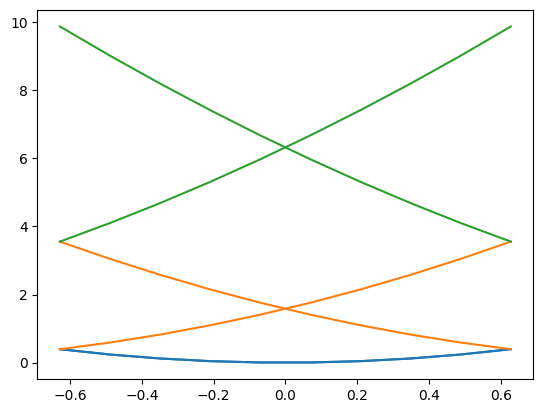

In [5]:
plot = mpl.figure(1,clear=True).add_subplot(111)

for i in range(3):
    l1 = (k+2*i*pi/a)**2
    l2 = (k-2*i*pi/a)**2
    plot.plot(k, l1, label=f'Band {i+1}', color='C'+str(i))
    plot.plot(k, l2, label=f'Band {i+1}', color='C'+str(i))
    
mpl.show()

**2D**

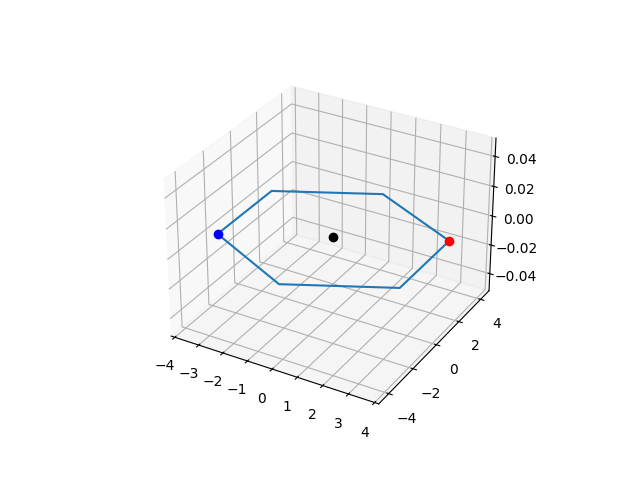

In [39]:
%matplotlib widget
plot3d = mpl.figure(2,clear=True).add_subplot(111, projection='3d')



plot3d.plot(vertices[:,0], vertices[:,1], 0)
plot3d.plot([0], [0], 0, color='k', marker='o')
plot3d.plot(k1[0], k1[1], 0, color='r', marker='o')
plot3d.plot(k2[0], k2[1], 0, color='b', marker='o')


# for x,y in lambdas:
#     l = ((k1+b1[0]*x+b2[0]*y)**2 + (k2+b1[1]*x+b2[1]*y)**2)
#     plot3d.plot_surface(
#         k1, k2, l, label=f'Band {x}, {y}',
#         alpha=0.5, cmap=mpl.cm.coolwarm, linewidth=0.7, antialiased=False, edgecolor='C'+str(abs(x)+abs(y))
#     )

# mpl.legend()
mpl.show()

**K Points**

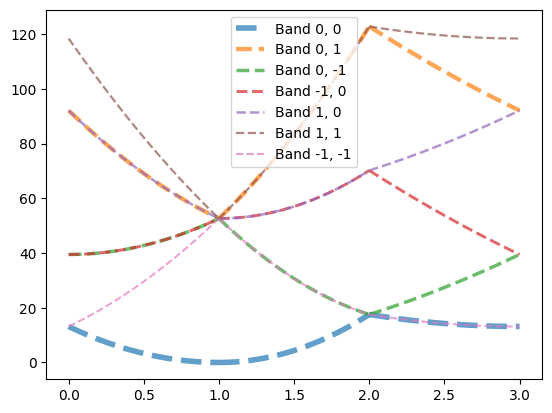

In [7]:
T=np.array([0,0])

# K=np.array([pi,pi])
# M=np.array([pi,0])

K=np.array([2*pi/np.sqrt(3),2*pi/3])
M=np.array([2*pi/np.sqrt(3),0])

t = np.linspace(0,1,25)

kt0 = np.array([t*(T)+(1-t)*(M) for t in t])
kt1 = np.array([t*(K)+(1-t)*(T) for t in t])
kt2 = np.array([t*(M)+(1-t)*(K) for t in t])

TKM_Plot = mpl.figure(3,clear=True).add_subplot(111)

i = 0
for x,y in lambdas:
    l0 = ((kt0[:,0]+b1[0]*x+b2[0]*y)**2 + (kt0[:,1]+b1[1]*x+b2[1]*y)**2)
    l1 = ((kt1[:,0]+b1[0]*x+b2[0]*y)**2 + (kt1[:,1]+b1[1]*x+b2[1]*y)**2)
    l2 = ((kt2[:,0]+b1[0]*x+b2[0]*y)**2 + (kt2[:,1]+b1[1]*x+b2[1]*y)**2)
    TKM_Plot.plot(t,l0,label=f'Band {x}, {y}',color='C'+str(i),alpha=0.7,linewidth=4/(0.3*i+1),linestyle='--')
    TKM_Plot.plot(t+1,l1,color='C'+str(i),alpha=0.7,linewidth=4/(0.3*i+1),linestyle='--')
    TKM_Plot.plot(t+2,l2,color='C'+str(i),alpha=0.7,linewidth=4/(0.3*i+1),linestyle='--')
    i += 1

TKM_Plot.legend()
mpl.show()

In [ ]:
print(kt1[:,0])
print(kt2[:,0])

[0.         0.15114995 0.30229989 0.45344984 0.60459979 0.75574974
 0.90689968 1.05804963 1.20919958 1.36034952 1.51149947 1.66264942
 1.81379936 1.96494931 2.11609926 2.26724921 2.41839915 2.5695491
 2.72069905 2.87184899 3.02299894 3.17414889 3.32529883 3.47644878
 3.62759873]
[3.62759873 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873
 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873
 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873
 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873 3.62759873
 3.62759873]
